# 07-MuJoCo仿真主循环


## 1. 本课目标：机器人世界的一帧

本篇对应《具身智能机器人实战》第 07 节《mujoco 仿真主循环》，副标题为“机器人世界的一帧”。上一节读取了 `qpos、qvel、ctrl`，本节认识仿真怎样随时间推进，使机器人的状态不断变化。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/07_mujoco仿真主循环.pptx` 全部 3 页：第 1 页为主题，第 2 页解释 `mj_step()`，第 3 页为品牌结束页。

课件给出了步进调用与物理计算示意，没有展示完整主循环。第 3、4 节将步长、查看器和可运行示例标为“工程补充”。未转录配套视频，也未读取网盘中的 `code.zip`。


## 2. mj_step：仿真的一次“心跳”

课件的核心调用是：

```python
mujoco.mj_step(model, data)
```

其中 `model` 保存模型和物理设置，`data` 保存当前状态与计算数据。调用后，引擎根据模型及当前输入推进一步仿真，更新状态。

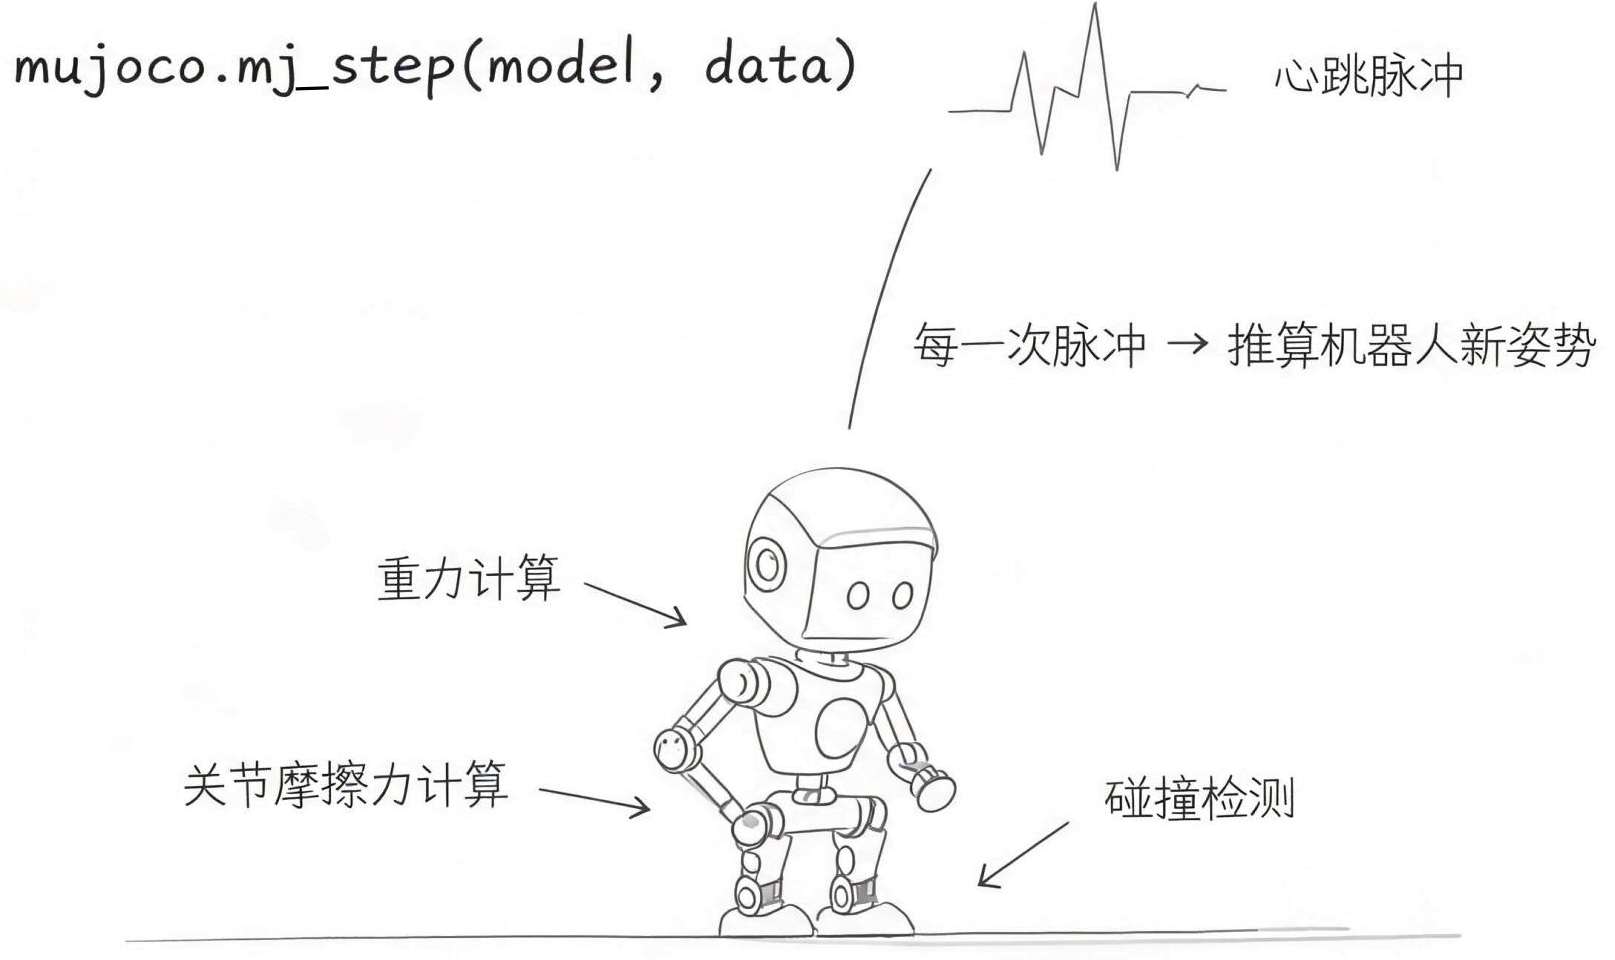

*原课件第 2 页，裁取步进调用和教学示意。课件将它比作“心跳脉冲”，每次脉冲推算机器人的新姿态。*

图中强调了三类物理因素：

| 因素 | 理解本次状态变化时关注的内容 |
|---|---|
| 重力计算 | 机器人会受到模型中重力设置的影响 |
| 关节摩擦力计算 | 关节运动可能受到已配置的摩擦等阻力影响 |
| 碰撞检测 | 身体与地面或其他部件的接触会影响运动 |

这些标注帮助理解物理步进涉及什么，并未列出引擎内部的全部算法或执行顺序。实际计算遵循模型配置，例如没有配置的关节摩擦不会凭空出现。

主循环重复调用 `mj_step()`，把前一步的结果作为后一步的起点。如果始终停留在初始化与读取阶段，仿真时间就不会继续前进。


## 3. 工程补充：主循环中的时间与显示

### 3.1 每次推进多少仿真时间

默认每调用一次 `mj_step(model, data)`，仿真时间推进一个 `model.opt.timestep`。`data.time` 记录仿真时间，单位为秒。

沿用前几篇核对的官方模型提交 `335c60e88772c26c7852d0abd6b3c7439037dd8f`，其 `serial_t800.xml` 设置 `timestep="0.002"`，即每步 2 毫秒。在步长不变、没有中途重置的情况下，100 步推进 `100 × 0.002 = 0.2` 秒仿真时间。

这只是模型里的时间尺度。电脑可能在短于或长于 0.2 秒的实际耗时内完成这 100 步。

### 3.2 输入、物理步进与画面刷新

一个便于理解的循环顺序是：先准备本步控制输入，调用 `mj_step()`，再把结果同步给查看器。下一轮根据需要重新读取状态并计算输入。

| 操作 | 作用 |
|---|---|
| 更新 `data.ctrl` | 准备执行器在本步使用的控制输入 |
| `mujoco.mj_step(model, data)` | 计算并积分，推进物理状态与仿真时间 |
| `viewer.sync()` | 同步仿真状态、显示设置与界面交互 |
| `time.sleep(...)` | 让程序等待，粗略控制相对于现实时间的运行速度 |

被动查看器 `launch_passive()` 由用户脚本负责推进物理。只调用 `viewer.sync()` 不会自动替脚本完成物理步进。`sleep()` 也不会增加 `data.time`，物理步长仍由模型设置决定。

这里的“一帧”是课件对一次状态推进的直观说法。物理步数和画面刷新次数可以分别安排，不能据此认定每个物理步都必须对应一张显示画面。

### 3.3 与前几篇的 mj_forward 有何区别

前几篇在读取初始位置或状态前使用 `mj_forward()`。它根据当前状态重新计算派生数据，**不做时间积分**。`mj_step()` 则把仿真推进到下一步。

因此，查看初始模型时可以停留在 `mj_forward()`，观察物理运动时需要不断步进。零控制输入也会产生重力和接触作用，不意味着机器人保持初始姿态。


## 4. 工程补充：运行一个有限步数的 T800 主循环

沿用第 03～06 篇的 `t800-load` 练习目录、官方模型与 `.venv`，新建 `simulate_t800.py`。下面默认运行 100 步，不打开窗口；增加 `--view` 后可以观察同一循环。

示例每步将 `ctrl` 设为零，用来观察物理步进，没有加入保持站立的控制器。图形模式下若机器人下沉或倒下，应结合这一条件理解。

```python
import argparse
from contextlib import nullcontext
from pathlib import Path
import time

import mujoco

parser = argparse.ArgumentParser(description="运行 T800 仿真主循环")
parser.add_argument(
    "--model", type=Path,
    default=Path(__file__).resolve().parent
    / "engineai_robotics_native_sdk/assets/resource/t800.xml",
)
parser.add_argument("--steps", type=int, default=100)
parser.add_argument("--view", action="store_true")
args = parser.parse_args()
if args.steps <= 0:
    parser.error("--steps 必须为正整数")

model = mujoco.MjModel.from_xml_path(str(args.model.expanduser().resolve()))
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)
steps_done = 0

if args.view:
    import mujoco.viewer
    viewer_context = mujoco.viewer.launch_passive(model, data)
else:
    viewer_context = nullcontext(None)

with viewer_context as viewer:
    for _ in range(args.steps):
        if viewer is not None and not viewer.is_running():
            break
        step_start = time.perf_counter()
        data.ctrl[:] = 0.0
        mujoco.mj_step(model, data)
        steps_done += 1

        if viewer is not None:
            viewer.sync()
            remaining = model.opt.timestep - (time.perf_counter() - step_start)
            if remaining > 0:
                time.sleep(remaining)

print(f"steps={steps_done}, timestep={model.opt.timestep:.3f}")
print(f"simulation_time={data.time:.3f}")
```

`nullcontext(None)` 让无窗口模式沿用同一段循环，此时 `viewer` 为 `None`。图形模式到达指定步数或关闭窗口后退出，`with` 负责清理查看器。

在 `t800-load` 目录的 PowerShell 中先运行无窗口检查：

```powershell
.\.venv\Scripts\python.exe simulate_t800.py --steps 100
```

本篇在 MuJoCo 3.4.0 与上述模型版本上实际运行，输出为：

```text
steps=100, timestep=0.002
simulation_time=0.200
```

这说明循环确实推进了 100 个物理步。计算中的浮点数可能有极小误差，示例按 3 位小数显示时间。

需要查看运动时，在同一目录执行：

```powershell
.\.venv\Scripts\python.exe simulate_t800.py --view --steps 1000
```

预期打开模型窗口，最多推进 2 秒仿真时间。循环用“步长减去本轮计算耗时”估算剩余等待时间，仅作粗略节奏控制，系统调度和渲染开销仍可能造成偏差。无窗口模式没有等待，会按电脑可完成的速度运行。

本次实际验证使用无窗口模式，未打开图形查看器。模型位于其他目录时，可以添加 `--model` 并指定保留完整资源目录的场景入口。


## 5. 本课检查与补充参考

完成本节，应能说明 `mj_step()` 怎样让状态和时间继续前进，区分物理步长、现实耗时与画面刷新，并用步数和 `data.time` 核对循环是否实际运行。

本篇补充脚本已在官方 T800 模型上执行 100 步，检查时间推进与状态数值有限，没有验证站立控制或真实硬件。

- [本篇版本的 T800 步长与模型配置](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml/serial_t800.xml)。
- [MuJoCo 3.4.0：mj_step](https://mujoco.readthedocs.io/en/3.4.0/APIreference/APIfunctions.html#mj-step)。
- [MuJoCo 3.4.0：mj_forward](https://mujoco.readthedocs.io/en/3.4.0/APIreference/APIfunctions.html#mj-forward)。
- [MuJoCo 3.4.0：被动查看器与计时示例](https://mujoco.readthedocs.io/en/3.4.0/python.html#passive-viewer)。
